# Task 3: Telecom Customer Churn Prediction (Random Forest & XGBoost)

**Objective:** Build an end-to-end classification pipeline using `OneHotEncoder`, class balancing (`SMOTE` and `scale_pos_weight`), `RandomForestClassifier`, and `XGBClassifier` with stratified cross-validation, ROC-AUC evaluation, confusion matrices, and top 10 feature importances.


## 1. Load Telco Customer Churn Dataset


In [1]:
# Install imbalanced-learn & xgboost if not already installed in your environment
# !pip install -q imbalanced-learn xgboost

import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Provided Telco Customer Churn dataset snippet (filters truncated trailing row if present)
raw_csv = """customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes
9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.1,1949.4,No
6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.8,3046.05,Yes
6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No
9763-GRSKD,Male,0,Yes,Yes,13,Yes,No,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Mailed check,49.95,587.45,No
7469-LKBCI,Male,0,No,No,16,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),18.95,326.8,No
8091-TTVAX,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),100.35,5681.1,No
0280-XJGEX,Male,0,No,No,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.7,5036.3,Yes
5129-JLPIS,Male,0,No,No,25,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,105.5,2686.05,No
3655-SNQYZ,Female,0,Yes,Yes,69,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),113.25,7895.15,No
8191-XWSZG,Female,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.65,1022.95,No
9959-WOFKT,Male,0,No,Yes,71,Yes,Yes,Fiber optic,Yes,No,Yes,No,Yes,Yes,Two year,No,Bank transfer (automatic),106.7,7382.25,No
4190-MFLUW,Female,0,Yes,Yes,10,Yes,No,DSL,No,No,Yes,Yes,No,No,Month-to-month,No,Credit card (automatic),55.2,528.35,Yes
4183-MYFRB,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,90.05,1862.9,No
8779-QRDMV,Male,1,No,No,1,No,No phone service,DSL,No,No,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,39.65,39.65,Yes
1680-VDCWW,Male,0,Yes,No,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Bank transfer (automatic),19.8,202.25,No
1066-JKSGK,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
3638-WEABW,Female,0,Yes,No,58,Yes,Yes,DSL,No,Yes,No,Yes,No,No,Two year,Yes,Credit card (automatic),59.9,3505.1,No
6322-HRPFA,Male,0,Yes,Yes,49,Yes,No,DSL,Yes,Yes,No,Yes,No,No,Month-to-month,No,Credit card (automatic),59.6,2970.3,No
6865-JZNKO,Female,0,No,No,30,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),55.3,1530.6,No
6467-CHFZW,Male,0,Yes,Yes,47,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.35,4749.15,Yes
8665-UTDHZ,Male,0,Yes,Yes,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,No,Electronic check,30.2,30.2,Yes
5248-YGIJN,Male,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),90.25,6369.45,No
8773-HHUOZ,Female,0,No,Yes,17,Yes,No,DSL,No,No,No,No,Yes,Yes,Month-to-month,Yes,Mailed check,64.7,1093.1,Yes
3841-NFECX,Female,1,Yes,No,71,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,No,No,Two year,Yes,Credit card (automatic),96.35,6766.95,No
4929-XIHVW,Male,1,Yes,No,2,Yes,No,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),95.5,181.65,No
6827-IEAUQ,Female,0,Yes,Yes,27,Yes,No,DSL,Yes,Yes,Yes,Yes,No,No,One year,No,Mailed check,66.15,1874.45,No
7310-EGVHZ,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Bank transfer (automatic),20.2,20.2,No
3413-BMNZE,Male,1,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Bank transfer (automatic),45.25,45.25,No
6234-RAAPL,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,No,Yes,Yes,No,Two year,No,Bank transfer (automatic),99.9,7251.7,No
6047-YHPVI,Male,0,No,No,5,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.7,316.9,Yes
6572-ADKRS,Female,0,No,No,46,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),74.8,3548.3,No
5380-WJKOV,Male,0,No,No,34,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,106.35,3549.25,Yes
8168-UQWWF,Female,0,No,No,11,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),97.85,1105.4,Yes
8865-TNMNX,Male,0,Yes,Yes,10,Yes,No,DSL,No,Yes,No,No,No,No,One year,No,Mailed check,49.55,475.7,No
9489-DEDVP,Female,0,Yes,Yes,70,Yes,Yes,DSL,Yes,Yes,No,No,Yes,No,Two year,Yes,Credit card (automatic),69.2,4872.35,No
9867-JCZSP,Female,0,Yes,Yes,17,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,418.25,No
4671-VJLCL,Female,0,No,No,63,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,Yes,Credit card (automatic),79.85,4861.45,No
4080-IIARD,Female,0,Yes,No,13,Yes,Yes,DSL,Yes,Yes,No,Yes,Yes,No,Month-to-month,Yes,Electronic check,76.2,981.45,No
3714-NTNFO,Female,0,No,No,49,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,84.5,3906.7,No
5948-UJZLF,Male,0,No,No,2,Yes,No,DSL,No,Yes,No,No,No,No,Month-to-month,No,Mailed check,49.25,97,No
7760-OYPDY,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,80.65,144.15,Yes
7639-LIAYI,Male,0,No,No,52,Yes,Yes,DSL,Yes,No,No,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),79.75,4217.8,No
2954-PIBKO,Female,0,Yes,Yes,69,Yes,Yes,DSL,Yes,No,Yes,Yes,No,No,Two year,Yes,Credit card (automatic),64.15,4254.1,No
8012-SOUDQ,Female,1,No,No,43,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Electronic check,90.25,3838.75,No
9420-LOJKX,Female,0,No,No,15,Yes,No,Fiber optic,Yes,Yes,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.1,1426.4,Yes
6575-SUVOI,Female,1,Yes,No,25,Yes,Yes,DSL,Yes,No,No,Yes,Yes,No,Month-to-month,Yes,Credit card (automatic),69.5,1752.65,No
7495-OOKFY,Female,1,Yes,No,8,Yes,Yes,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Credit card (automatic),80.65,633.3,Yes
4667-QONEA,Female,1,Yes,Yes,60,Yes,No,DSL,Yes,Yes,Yes,Yes,No,Yes,One year,Yes,Credit card (automatic),74.85,4456.35,No
1658-BYGOY,Male,1,No,No,18,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,1752.55,Yes
8769-KKTPH,Female,0,Yes,Yes,63,Yes,Yes,Fiber optic,Yes,No,No,No,Yes,Yes,One year,Yes,Credit card (automatic),99.65,6311.2,No
5067-XJQFU,Male,1,Yes,Yes,66,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,108.45,7076.35,No
3957-SQXML,Female,0,Yes,Yes,34,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),24.95,894.3,No
5954-BDFSG,Female,0,No,No,72,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),107.5,7853.7,No
0434-CSFON,Female,0,Yes,No,47,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.5,4707.1,No
1215-FIGMP,Male,0,No,No,60,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Bank transfer (automatic),89.9,5450.7,No
0526-SXDJP,Male,0,Yes,No,72,No,No phone service,DSL,Yes,Yes,Yes,No,No,No,Two year,No,Bank transfer (automatic),42.1,2962,No
0557-ASKVU,Female,0,Yes,Yes,18,Yes,No,DSL,No,No,Yes,Yes,No,No,One year,Yes,Credit card (automatic),54.4,957.1,No
5698-BQJOH,Female,0,No,No,9,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,94.4,857.25,Yes
5122-CYFXA,Female,0,No,No,3,Yes,No,DSL,No,Yes,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,75.3,244.1,No
8627-ZYGSZ,Male,0,Yes,No,47,Yes,Yes,Fiber optic,No,Yes,No,No,No,No,One year,Yes,Electronic check,78.9,3650.35,No
3410-YOQBQ,Female,0,No,No,31,Yes,No,DSL,No,Yes,Yes,Yes,Yes,Yes,Two year,No,Mailed check,79.2,2497.2,No
3170-NMYVV,Female,0,Yes,Yes,50,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),20.15,930.9,No
7410-OIEDU,Male,0,No,No,10,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Mailed check,79.85,887.35,No
2273-QCKXA,Male,0,No,No,1,Yes,No,DSL,No,No,No,Yes,No,No,Month-to-month,No,Mailed check,49.05,49.05,No
0731-EBJQB,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Electronic check,20.4,1090.65,No
1891-QRQSA,Male,1,Yes,Yes,64,Yes,Yes,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),111.6,7099,No
8028-PNXHQ,Male,0,Yes,Yes,62,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),24.25,1424.6,No
5630-AHZIL,Female,0,No,Yes,3,Yes,No,DSL,Yes,No,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),64.5,177.4,No
2673-CXQEU,Female,1,No,No,56,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,Yes,One year,No,Electronic check,110.5,6139.5,No
6416-JNVRK,Female,0,No,No,46,Yes,No,DSL,No,No,No,No,No,Yes,One year,No,Credit card (automatic),55.65,2688.85,No
5590-ZSKRV,Female,0,Yes,Yes,8,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,No,Mailed check,54.65,482.25,No
0191-ZHSKZ,Male,1,No,No,30,Yes,No,DSL,Yes,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,74.75,2111.3,No
3887-PBQAO,Female,0,Yes,Yes,45,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Credit card (automatic),25.9,1216.6,No
5919-TMRGD,Female,0,No,Yes,1,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,79.35,79.35,Yes
8108-UXRQN,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,50.55,565.35,No
9191-MYQKX,Female,0,Yes,No,7,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,Yes,Bank transfer (automatic),75.15,496.9,Yes
9919-YLNNG,Female,0,No,No,42,Yes,No,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.8,4327.5,No
0318-ZOPWS,Female,0,Yes,No,49,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.15,973.35,No
4445-ZJNMU,Male,0,No,No,9,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.3,918.75,No
4808-YNLEU,Female,0,Yes,No,35,Yes,No,DSL,Yes,No,No,No,Yes,No,One year,Yes,Bank transfer (automatic),62.15,2215.45,No
1862-QRWPE,Female,0,Yes,Yes,48,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),20.65,1057,No
2796-NNUFI,Female,0,Yes,Yes,46,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,19.95,927.1,No
3016-KSVCP,Male,0,Yes,No,29,No,No phone service,DSL,No,No,No,No,Yes,No,Month-to-month,No,Mailed check,33.75,1009.25,No
4767-HZZHQ,Male,0,Yes,Yes,30,Yes,No,Fiber optic,No,Yes,Yes,No,No,No,Month-to-month,No,Bank transfer (automatic),82.05,2570.2,No
2424-WVHPL,Male,1,No,No,1,Yes,No,Fiber optic,No,No,No,Yes,No,No,Month-to-month,No,Electronic check,74.7,74.7,No
7233-PAHHL,Male,0,Yes,Yes,66,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Mailed check,84,5714.25,No
6067-NGCEU,Female,0,No,No,65,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),111.05,7107,No
9848-JQJTX,Male,0,No,No,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),100.9,7459.05,No
8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21,1107.2,No
4598-XLKNJ,Female,1,Yes,No,25,Yes,No,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,98.5,2514.5,Yes
6380-ARCEH,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.2,20.2,No
3679-XASPY,Female,0,Yes,Yes,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,19.45,19.45,No
7123-WQUHX,Male,0,No,No,38,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,No,One year,No,Bank transfer (automatic),95,3605.6,No
5386-THSLQ,Female,1,Yes,No,66,No,No phone service,DSL,No,Yes,Yes,No,Yes,No,One year,No,Bank transfer (automatic),45.55,3027.25,No
3192-NQECA,Male,0,Yes,No,68,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),110,7611.85,Yes
6180-YBIQI,Male,0,No,No,5,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,24.3,100.2,No
6728-DKUCO,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,No,No,Yes,Yes,One year,Yes,Electronic check,104.15,7303.05,No
9750-BOOHV,Female,0,No,No,32,No,No phone service,DSL,Yes,No,No,No,No,No,One year,No,Mailed check,30.15,927.65,No
8597-CWYHH,Male,0,No,No,43,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,One year,No,Mailed check,94.35,3921.3,No
2848-YXSMW,Male,0,Yes,Yes,72,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),19.4,1363.25,No
0486-HECZI,Male,0,Yes,No,55,Yes,Yes,Fiber optic,Yes,Yes,No,No,Yes,No,Month-to-month,Yes,Electronic check,96.75,5238.9,Yes
4549-ZDQYY,Female,0,No,No,52,Yes,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Credit card (automatic),57.95,3042.25,No
5712-AHQNN,Female,0,No,No,43,Yes,No,Fiber optic,No,Yes,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,91.65,3954.1,No
4846-WHAFZ,Female,1,Yes,No,37,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,76.5,2868.15,Yes
5256-SKJGO,Female,0,Yes,Yes,64,No,No phone service,DSL,No,Yes,No,Yes,Yes,Yes,Two year,Yes,Electronic check,54.6,3423.5,No
3071-VBYPO,Male,0,Yes,Yes,3,Yes,No,Fiber optic,Yes,Yes,No,No,Yes,No,Month-to-month,No,Electronic check,89.85,248.4,No
9560-BBZXK,Female,0,No,No,36,No,No phone service,DSL,Yes,No,No,No,No,No,Two year,No,Bank transfer (automatic),31.05,1126.35,No
5299-RULOA,Female,0,Yes,Yes,10,Yes,Yes,Fiber optic,Yes,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.25,1064.65,Yes
8402-OOOHJ,Female,0,No,No,41,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.65,835.15,No
9445-ZUEQE,Male,0,Yes,Yes,27,Yes,Yes,Fiber optic,No,Yes,No,Yes,No,No,Month-to-month,Yes,Credit card (automatic),85.2,2151.6,No
1091-SOZGA,Female,0,Yes,Yes,56,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),99.8,5515.45,No
2928-HLDBA,Female,0,No,No,6,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.7,112.75,No
0404-SWRVG,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,74.4,229.55,Yes
6497-TILVL,Female,0,Yes,Yes,7,Yes,No,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,50.7,350.35,No
7219-TLZHO,Female,0,Yes,Yes,4,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.85,62.9,No
4622-YNKIJ,Male,0,No,No,33,Yes,No,Fiber optic,Yes,No,No,Yes,Yes,No,Two year,Yes,Electronic check,88.95,3027.65,No
4412-YLTKF,Female,1,No,No,27,Yes,Yes,Fiber optic,No,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,78.05,2135.5,Yes
6734-PSBAW,Male,0,Yes,No,72,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),23.55,1723.95,No
3930-ZGWVE,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.75,19.75,No
2639-UGMAZ,Male,1,No,No,71,No,No phone service,DSL,Yes,Yes,No,No,Yes,Yes,One year,Yes,Electronic check,56.45,3985.35,No
2876-GZYZC,Female,0,No,No,13,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,85.95,1215.65,No
6207-WIOLX,Female,0,Yes,Yes,25,No,No phone service,DSL,Yes,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),58.6,1502.65,Yes
8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No
3091-FYHKI,Male,0,No,No,1,No,No phone service,DSL,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,35.45,35.45,Yes
2372-HWUHI,Male,0,No,No,2,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.35,81.25,Yes
7799-LGRDP,Female,0,No,No,43,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),25.7,1188.2,No
7850-VWJUU,Female,0,No,No,23,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),75,1778.5,No
3774-VBNXY,Female,0,Yes,Yes,64,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.2,1277.75,No
6217-KDYWC,Male,0,No,Yes,57,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,19.6,1170.55,No
0390-DCFDQ,Female,1,Yes,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.45,70.45,Yes
3146-MSEGF,Female,1,Yes,Yes,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),88.05,6425.65,No
4080-OGPJL,Female,0,No,No,8,Yes,Yes,DSL,Yes,No,No,Yes,No,Yes,Month-to-month,No,Electronic check,71.15,563.65,Yes
1095-WGNGG,Female,0,Yes,No,61,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),101.05,5971.25,No
2636-SJDOU,Male,0,No,No,64,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,No,One year,Yes,Credit card (automatic),84.3,5289.05,No
1131-QQZEB,Male,1,Yes,No,71,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),23.95,1756.2,No
5716-EZXZN,Female,0,Yes,Yes,65,Yes,Yes,Fiber optic,Yes,Yes,No,Yes,Yes,No,Two year,Yes,Credit card (automatic),99.05,6416.7,No
6837-BJYDQ,Male,0,No,No,3,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,19.6,61.35,No
2135-RXIHG,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,45.65,45.65,Yes
6440-DKQGE,Male,0,No,Yes,30,Yes,No,DSL,No,Yes,Yes,No,Yes,No,One year,No,Credit card (automatic),64.5,1929.95,No
3466-BYAVD,Male,0,Yes,Yes,15,Yes,No,DSL,No,Yes,Yes,Yes,No,Yes,Month-to-month,Yes,Mailed check,69.5,1071.4,No
3780-YVMFA,Female,0,Yes,Yes,8,Yes,No,DSL,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,68.55,564.35,No
3874-EQOEP,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,No,Mailed check,95,655.5,Yes
1679-JRFBR,Female,0,Yes,Yes,70,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),108.15,7930.55,No
9073-ZZIAY,Male,0,Yes,Yes,62,Yes,No,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Electronic check,86.1,5215.25,No
3077-RSNTJ,Female,0,Yes,Yes,6,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.7,113.5,No
6551-GNYDG,Female,0,Yes,Yes,14,Yes,No,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),80.9,1152.8,No
9167-APMXZ,Female,0,No,No,22,Yes,Yes,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Bank transfer (automatic),84.15,1821.95,No
2749-CTKAJ,Male,0,Yes,Yes,22,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.15,419.9,No
6371-NZYEG,Male,0,Yes,Yes,16,Yes,No,DSL,Yes,No,Yes,No,Yes,No,Two year,No,Mailed check,64.25,1024,No
7554-NEWDD,Male,0,No,No,10,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),25.7,251.6,No
8992-VONJD,Female,0,No,Yes,13,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,56,764.55,No
0867-MKZVY,Female,0,Yes,No,20,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Electronic check,82.4,1592.35,Yes
4482-EWFMI,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.7,135.2,No
4648-YPBTM,Male,0,No,No,53,Yes,Yes,DSL,No,Yes,Yes,Yes,No,Yes,Two year,Yes,Bank transfer (automatic),73.9,3958.25,No
2907-ILJBN,Female,0,Yes,Yes,11,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.6,233.9,No
6345-FZOQH,Male,0,Yes,No,69,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.9,1363.45,No
3376-BMGFE,Female,0,No,No,4,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),70.9,273,Yes
5997-OPVFA,Male,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),89.05,6254.45,No
3445-HXXGF,Male,1,Yes,No,58,No,No phone service,DSL,No,Yes,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,45.3,2651.2,Yes
1159-WFSGR,Female,0,Yes,Yes,16,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,20.4,321.4,No
7654-YWJUF,Male,0,Yes,No,43,Yes,No,Fiber optic,Yes,No,Yes,Yes,No,No,One year,Yes,Bank transfer (automatic),84.25,3539.25,No
1875-QIVME,Female,0,Yes,No,2,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.4,242.8,Yes
6727-IOTLZ,Male,0,Yes,No,14,Yes,No,DSL,No,Yes,Yes,Yes,Yes,Yes,Two year,No,Mailed check,81.95,1181.75,No
0691-JVSYA,Female,0,Yes,No,53,Yes,No,Fiber optic,No,No,Yes,No,Yes,Yes,One year,Yes,Bank transfer (automatic),94.85,5000.2,Yes
5918-VUKWP,Female,0,No,No,32,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Bank transfer (automatic),20.55,654.55,No
1744-JHKYS,Female,0,Yes,No,34,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,24.7,780.2,No
2656-FMOKZ,Female,1,No,No,15,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.45,1145.7,Yes
2070-FNEXE,Female,1,No,No,7,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Bank transfer (automatic),76.45,503.6,Yes
5947-SGKCL,Female,0,Yes,Yes,15,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),105.35,1559.25,No
3712-PKXZA,Male,0,Yes,No,61,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Credit card (automatic),20.55,1252,No
6317-YPKDH,Female,0,No,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,No,Bank transfer (automatic),29.95,29.95,Yes
6582-OIVSP,Female,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,45.3,45.3,No
9367-WXLCH,Male,0,No,No,8,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,No,Bank transfer (automatic),84.5,662.65,Yes
5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.75,2453.3,No
1918-ZBFQJ,Female,0,No,No,13,Yes,No,Fiber optic,No,Yes,Yes,No,No,No,Month-to-month,Yes,Electronic check,79.25,1111.65,Yes
1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.8,24.8,Yes
4827-USJHP,Male,0,No,No,20,Yes,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,51.8,1023.85,No
8167-GJLRN,Male,0,No,No,3,No,No phone service,DSL,No,No,No,Yes,No,No,Month-to-month,No,Electronic check,30.4,82.15,No
0956-SYCWG,Female,0,No,No,13,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Electronic check,19.65,244.8,No
8017-UVSZU,Female,0,Yes,No,40,Yes,Yes,DSL,No,Yes,No,No,No,No,Month-to-month,No,Credit card (automatic),56.6,2379.1,No
7100-FQPRV,Male,0,Yes,Yes,43,Yes,Yes,DSL,Yes,No,No,Yes,No,Yes,One year,Yes,Credit card (automatic),71.9,3173.35,No
2472-OVKUP,Male,0,Yes,No,6,Yes,No,Fiber optic,No,Yes,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,91,531,Yes
2984-RGEYA,Female,0,Yes,Yes,69,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.75,1375.4,No
9680-NIAUV,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Credit card (automatic),109.7,8129.3,No
2146-EGVDT,Male,0,Yes,Yes,59,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),19.3,1192.7,No
2604-IJPDU,Female,0,Yes,No,20,Yes,No,Fiber optic,Yes,Yes,No,Yes,Yes,No,Month-to-month,Yes,Electronic check,96.55,1901.65,No
9178-JHUVJ,Male,0,Yes,Yes,24,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),24.1,587.4,No
6168-YBYNP,Male,0,No,No,59,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,111.35,6519.75,No
7255-SSFBC,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),112.25,8041.65,No
3645-DEYGF,Male,0,No,Yes,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.75,20.75,No
9323-HGFWY,Female,0,Yes,No,27,Yes,No,Fiber optic,Yes,No,No,Yes,Yes,Yes,One year,Yes,Credit card (automatic),101.9,2681.15,No
8544-GOQSH,Female,0,No,No,14,Yes,No,Fiber optic,No,Yes,No,Yes,No,No,Month-to-month,Yes,Credit card (automatic),80.05,1112.3,No
3363-DTIVD,Male,0,Yes,Yes,71,Yes,Yes,Fiber optic,Yes,No,Yes,No,Yes,Yes,Two year,No,Electronic check,105.55,7405.5,No
7018-WBJNK,Male,0,No,Yes,13,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),78.3,1033.95,No
9142-KZXOP,Male,0,No,No,44,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),68.85,2958.95,No
7674-YTAFD,Female,0,No,No,33,Yes,No,Fiber optic,No,Yes,No,Yes,No,No,One year,Yes,Bank transfer (automatic),79.95,2684.85,No
6348-SNFUS,Male,0,Yes,Yes,72,No,No phone service,DSL,Yes,Yes,Yes,Yes,No,Yes,Two year,Yes,Credit card (automatic),55.45,4179.2,No
1285-OKIPP,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,Yes,Month-to-month,No,Electronic check,79.9,79.9,Yes
7825-ECJRF,Female,0,No,No,19,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,106.6,1934.45,Yes
1347-KTTTA,Male,0,Yes,No,64,Yes,No,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,One year,Yes,Credit card (automatic),102.45,6654.1,No
7841-TZDMQ,Male,0,No,No,2,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),46,84.5,Yes
4195-NZGTA,Female,0,No,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,25.25,25.25,No
7157-SMCFK,Male,0,No,Yes,61,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.75,1124.2,No
4709-LKHYG,Female,0,Yes,Yes,29,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Electronic check,20,540.05,No
2504-DSHIH,Male,1,Yes,No,23,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,No,Electronic check,86.8,1975.85,No
0699-NDKJM,Female,0,Yes,No,57,No,No phone service,DSL,Yes,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),58.75,3437.45,No
9286-BHDQG,Male,0,Yes,Yes,72,No,No phone service,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Credit card (automatic),45.25,3139.8,No
0230-WEQUW,Male,0,Yes,No,66,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),56.6,3789.2,No
2040-LDIWQ,Male,0,Yes,Yes,65,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),84.2,5324.5,No
6496-JDSSB,Female,0,No,No,8,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Bank transfer (automatic),80,624.6,No
9408-SSNVZ,Female,0,No,No,4,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.15,268.35,Yes
4443-EMBNA,Female,0,Yes,No,71,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),24.75,1836.9,No
6469-MRVET,Male,0,Yes,Yes,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Electronic check,20.2,20.2,No
0"""

lines = raw_csv.strip().splitlines()
expected_cols = len(lines[0].split(","))
clean_lines = [line for line in lines if len(line.split(",")) == expected_cols]
df = pd.read_csv(io.StringIO("\n".join(clean_lines)))

# Uncomment below if running on the full Telco CSV file:
# df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (223, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Cleaning: Convert `TotalCharges` to Numeric & Handle Nulls


In [2]:
# Drop unique identifier column
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Convert TotalCharges to numeric (coercing blank strings to NaN) and handle nulls
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values before imputation:\n", df.isnull().sum()[df.isnull().sum() > 0])

# Encode target variable: Yes -> 1, No -> 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("\nTarget Class Distribution:")
print(df["Churn"].value_counts(normalize=True).rename("Proportion").round(4))


Missing values before imputation:
 Series([], dtype: int64)

Target Class Distribution:
Churn
0    0.7623
1    0.2377
Name: Proportion, dtype: float64


## 3. Train/Test Split & Preprocessing (`OneHotEncoder` + `StandardScaler`)


In [3]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [col for col in X.columns if col not in numeric_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")


Train samples: 178 | Test samples: 45


## 4. Balance Classes (`SMOTE` & `scale_pos_weight`) & Train Models with 5-Fold Cross-Validation


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Calculate class imbalance ratio for XGBoost scale_pos_weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

# 1. Random Forest with SMOTE oversampling inside CV pipeline (prevents data leakage)
rf_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42, k_neighbors=3)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_split=4,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. XGBoost with scale_pos_weight class balancing
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Cross-Validation ROC-AUC Scores
rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring="roc_auc")
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=cv, scoring="roc_auc")

# Fit on full training split & evaluate on holdout test set
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]
xgb_probs = xgb_pipeline.predict_proba(X_test)[:, 1]

rf_preds = rf_pipeline.predict(X_test)
xgb_preds = xgb_pipeline.predict(X_test)

results_df = pd.DataFrame([
    {
        "Model": "Random Forest (SMOTE)",
        "5-Fold CV ROC-AUC": f"{rf_cv_scores.mean():.4f} ± {rf_cv_scores.std():.4f}",
        "Test ROC-AUC": round(float(roc_auc_score(y_test, rf_probs)), 4)
    },
    {
        "Model": "XGBoost (scale_pos_weight)",
        "5-Fold CV ROC-AUC": f"{xgb_cv_scores.mean():.4f} ± {xgb_cv_scores.std():.4f}",
        "Test ROC-AUC": round(float(roc_auc_score(y_test, xgb_probs)), 4)
    }
])

print(results_df.to_string(index=False))
print("\n--- Random Forest Classification Report ---")
print(classification_report(y_test, rf_preds, target_names=["No Churn", "Churn"]))
print("--- XGBoost Classification Report ---")
print(classification_report(y_test, xgb_preds, target_names=["No Churn", "Churn"]))


                     Model 5-Fold CV ROC-AUC  Test ROC-AUC
     Random Forest (SMOTE)   0.8217 ± 0.1270        0.8583
XGBoost (scale_pos_weight)   0.8022 ± 0.0910        0.8182

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87        34
       Churn       0.62      0.45      0.53        11

    accuracy                           0.80        45
   macro avg       0.73      0.68      0.70        45
weighted avg       0.79      0.80      0.79        45

--- XGBoost Classification Report ---
              precision    recall  f1-score   support

    No Churn       0.88      0.88      0.88        34
       Churn       0.64      0.64      0.64        11

    accuracy                           0.82        45
   macro avg       0.76      0.76      0.76        45
weighted avg       0.82      0.82      0.82        45



## 5. Evaluate ROC-AUC Curves & Confusion Matrices


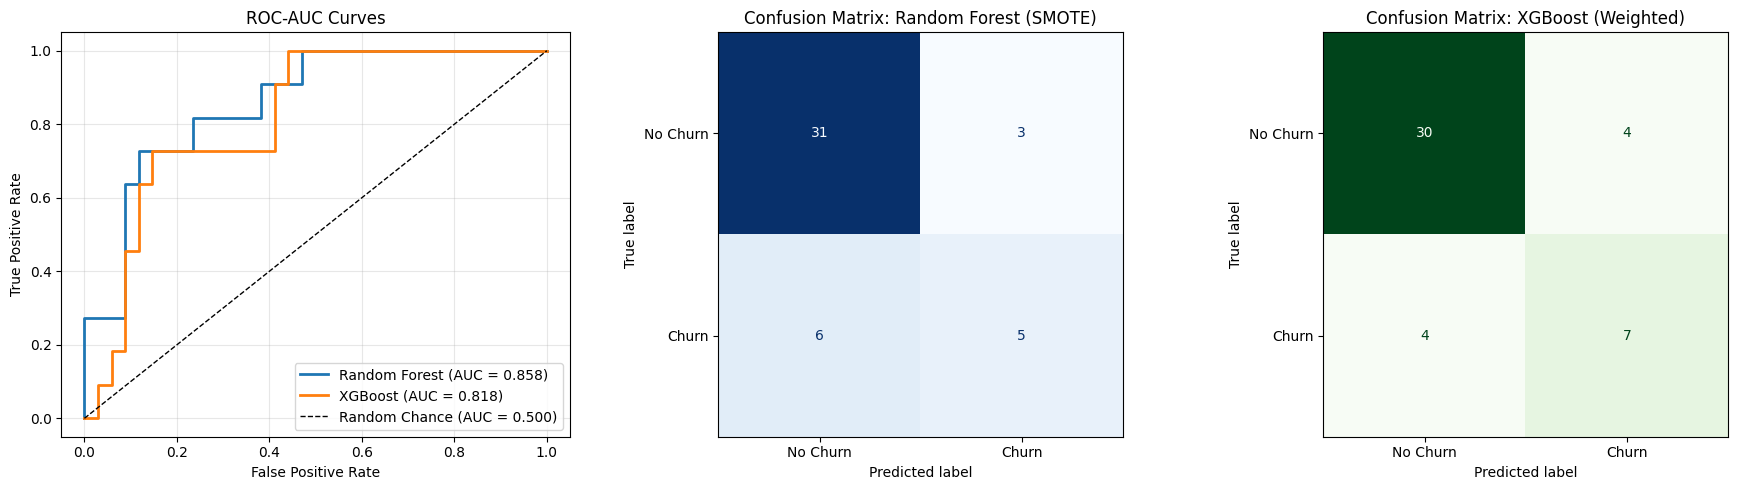

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC-AUC Curve Comparison
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)

axes[0].plot(fpr_rf, tpr_rf, linewidth=2, label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.3f})")
axes[0].plot(fpr_xgb, tpr_xgb, linewidth=2, label=f"XGBoost (AUC = {roc_auc_score(y_test, xgb_probs):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random Chance (AUC = 0.500)")
axes[0].set_title("ROC-AUC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# 2. Confusion Matrix — Random Forest
ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_preds), display_labels=["No Churn", "Churn"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion Matrix: Random Forest (SMOTE)")

# 3. Confusion Matrix — XGBoost
ConfusionMatrixDisplay(
    confusion_matrix(y_test, xgb_preds), display_labels=["No Churn", "Churn"]
).plot(ax=axes[2], cmap="Greens", colorbar=False)
axes[2].set_title("Confusion Matrix: XGBoost (Weighted)")

plt.tight_layout()
plt.show()


## 6. Top 10 Most Influential Feature Importances


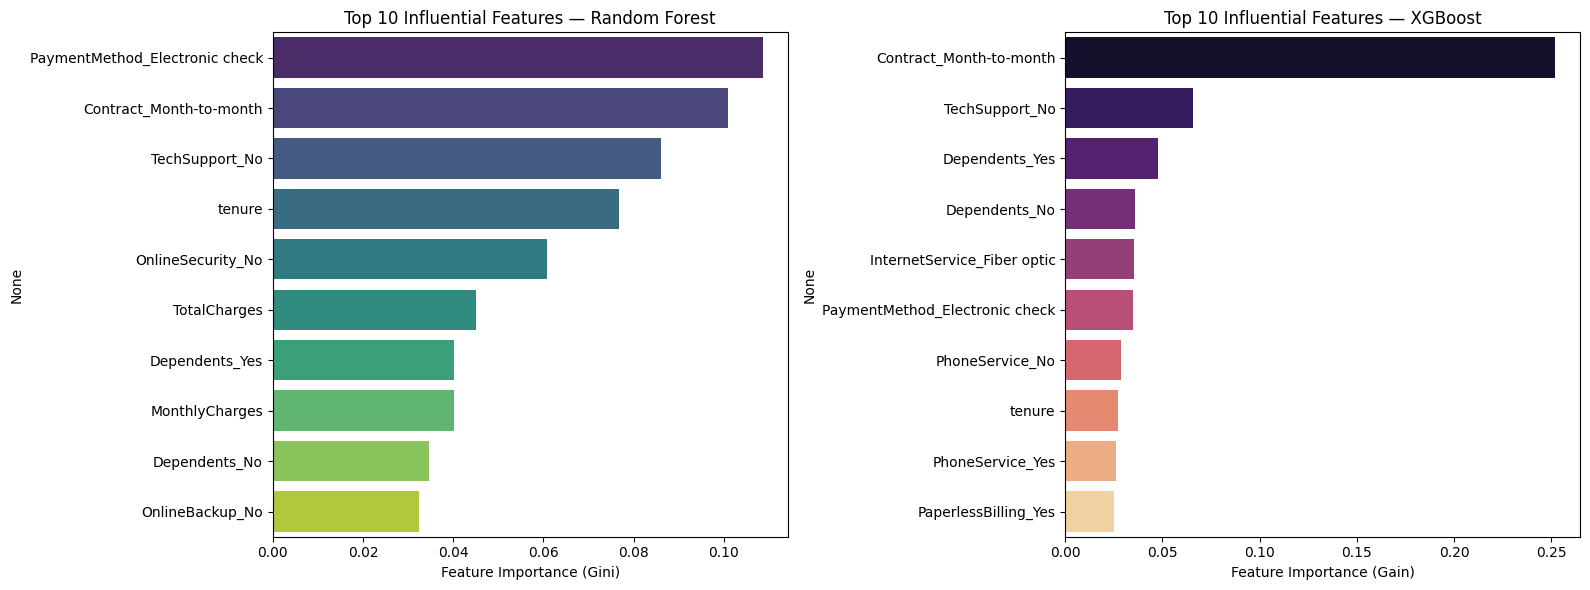

In [6]:
# Extract encoded feature names from the fitted preprocessor
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
ohe_features = fitted_preprocessor.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(categorical_features)
all_feature_names = np.concatenate([numeric_features, ohe_features])

rf_importances = pd.Series(
    rf_pipeline.named_steps["classifier"].feature_importances_, index=all_feature_names
).sort_values(ascending=False).head(10)

xgb_importances = pd.Series(
    xgb_pipeline.named_steps["classifier"].feature_importances_, index=all_feature_names
).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=rf_importances.values, y=rf_importances.index, palette="viridis", ax=axes[0])
axes[0].set_title("Top 10 Influential Features — Random Forest")
axes[0].set_xlabel("Feature Importance (Gini)")

sns.barplot(x=xgb_importances.values, y=xgb_importances.index, palette="magma", ax=axes[1])
axes[1].set_title("Top 10 Influential Features — XGBoost")
axes[1].set_xlabel("Feature Importance (Gain)")

plt.tight_layout()
plt.show()
